# 01 - Análisis exploratorio de datos (EDA)

**Problema:** predecir los casos semanales de dengue en el departamento de Lima para las próximas 4 semanas.

**Dataset:** "Dengue" (Kaggle, `stefanychavezherrera/dengue`). Reúne 5 archivos: vigilancia de casos del CDC Perú-MINSA 2000-2024 (datos abiertos, licencia ODC-BY), clima semanal por celda de grilla (NASA POWER / MERRA-2, 2010-2024), ICEN mensual (IGP/ENFEN), distritos con centroides y mapa distrito-celda.

**Alcance:** 2010-2024 (el clima empieza en 2010), departamento de Lima (81 distritos). Los datos crudos no se suben al repo (~200 MB); se regeneran con `python src/preprocessing.py` (ver `data/raw/README.md`).

**Enfoque (el del curso):** primero calidad de datos, luego faltantes, outliers, escalas y correlaciones, y al final cómo partir los datos sin fuga de información. Aquí solo se diagnostica y se decide; lo que aprende estadísticos (imputar, escalar) irá dentro de un `Pipeline` ajustado solo con train.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split

PROC = Path('../data/processed')
PLOTS = Path('../results/plots/eda')
PLOTS.mkdir(parents=True, exist_ok=True)

sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
LIMA_C, OTRO_C = '#C0392B', '#7F8C8D'

lima = pd.read_csv(PROC / 'lima_semanal.csv', parse_dates=['fecha_inicio'])
deps = pd.read_csv(PROC / 'departamentos_semanal.csv', parse_dates=['fecha_inicio'])
clim = pd.read_csv(PROC / 'clima_departamentos.csv')
cal = pd.read_csv(PROC / 'calidad_vigilancia.csv').set_index('metrica')['valor']

print('Lima semanal:', lima.shape, '| rango:', lima.fecha_inicio.min().date(), 'a', lima.fecha_inicio.max().date())
lima.head()

Lima semanal: (782, 25) | rango: 2010-01-03 a 2024-12-22


,ano,semana,fecha_inicio,casos,temp_media,temp_max,temp_min,precip_total,precip_max_d,dias_lluvia,...,temp_media_lag8,precip_total_lag2,precip_total_lag4,precip_total_lag6,precip_total_lag8,hum_rel_lag2,hum_rel_lag4,hum_rel_lag6,hum_rel_lag8,icen
0,2010,1,2010-01-03,0,19.078325,23.556790,15.874938,0.659136,0.373951,0.172840,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.35
1,2010,2,2010-01-10,0,19.523704,24.231728,16.572593,0.387531,0.197037,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.35
2,2010,3,2010-01-17,0,19.923598,24.516790,16.888642,0.161605,0.126296,0.012346,...,NaN,0.659136,NaN,NaN,NaN,76.199312,NaN,NaN,NaN,0.35
3,2010,4,2010-01-24,0,20.001728,24.664568,16.260370,0.506667,0.194938,0.024691,...,NaN,0.387531,NaN,NaN,NaN,74.912663,NaN,NaN,NaN,0.35
4,2010,5,2010-01-31,0,20.763386,25.557284,17.173086,1.176049,0.807654,0.222222,...,NaN,0.161605,0.659136,NaN,NaN,73.142857,76.199312,NaN,NaN,0.18


## 1. Calidad de los datos

Se revisan las cinco dimensiones vistas en clase. Las cifras de la vigilancia salen del archivo crudo (un caso por fila, 937,119 filas en 2010-2024; 122,073 son de Lima).

In [2]:
calidad = pd.DataFrame([
    ('Completitud', '¿Faltan valores?',
     f"localidad vacía en {cal['pct_localidad_nula_lima']} % de Lima ({cal['pct_localidad_nula']} % en el país); ubigeo completo; 8 semanas con rezagos vacíos",
     'No se usa localidad. Las 8 primeras semanas de 2010 se descartan (sección 2)'),
    ('Validez', '¿Está en el rango permitido?',
     f"semana fuera de 1-53: {int(cal['semana_fuera_1_53_lima'])}; ubigeo que no empieza en 15: {int(cal['ubigeo_no_15_lima'])}; "
     f"edad en años > 100: {int(cal['edad_anios_mayor_100_lima'])}; clima dentro de rangos físicos plausibles (sección 4)",
     'Sin cambios. Las 5 edades extremas no se usan como variable'),
    ('Consistencia', '¿Mismo formato y sin contradicciones?',
     f"ubigeo siempre de 6 dígitos ({int(cal['ubigeo_no_6_digitos_lima'])} excepciones) si se lee como texto; "
     'leído como número pierde el cero inicial; año con 52 o 53 semanas',
     'Leer ubigeo como str. Usar la semana epidemiológica CDC (domingo a sábado)'),
    ('Unicidad', '¿Hay duplicados?',
     f"{cal['pct_filas_duplicadas']} % de filas idénticas en el país, {cal['pct_duplicadas_lima']} % en Lima",
     'NO se eliminan: cada fila es un caso y no hay identificador de paciente'),
    ('Actualidad', '¿Está vigente?',
     'Vigilancia hasta 2024 (la ficha oficial la marca como provisional); clima hasta 2024',
     'Los datos 2025-2026 existen solo en boletines PDF del CDC: limitación declarada'),
], columns=['Dimensión', 'Pregunta', 'Hallazgo', 'Decisión'])
pd.set_option('display.max_colwidth', None)
calidad.style.hide(axis='index').set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'})

Dimensión,Pregunta,Hallazgo,Decisión
Completitud,¿Faltan valores?,localidad vacía en 39.3 % de Lima (12.2 % en el país); ubigeo completo; 8 semanas con rezagos vacíos,No se usa localidad. Las 8 primeras semanas de 2010 se descartan (sección 2)
Validez,¿Está en el rango permitido?,semana fuera de 1-53: 0; ubigeo que no empieza en 15: 0; edad en años > 100: 5; clima dentro de rangos físicos plausibles (sección 4),Sin cambios. Las 5 edades extremas no se usan como variable
Consistencia,¿Mismo formato y sin contradicciones?,ubigeo siempre de 6 dígitos (0 excepciones) si se lee como texto; leído como número pierde el cero inicial; año con 52 o 53 semanas,Leer ubigeo como str. Usar la semana epidemiológica CDC (domingo a sábado)
Unicidad,¿Hay duplicados?,"15.2 % de filas idénticas en el país, 20.9 % en Lima",NO se eliminan: cada fila es un caso y no hay identificador de paciente
Actualidad,¿Está vigente?,Vigilancia hasta 2024 (la ficha oficial la marca como provisional); clima hasta 2024,Los datos 2025-2026 existen solo en boletines PDF del CDC: limitación declarada


**Por qué no se eliminan los duplicados.** Dos casos distintos del mismo distrito, semana, edad y sexo producen filas idénticas. Eliminarlas bajaría los conteos justo en las semanas con más casos, que es lo que se quiere predecir.

**Semanas sin filas.** Una semana sin ninguna fila no es dato faltante: es una semana con 0 casos. Se completan con 0 al construir la grilla semanal.

### EDA mínimo de la tabla semanal

In [3]:
print('shape:', lima.shape)
print('duplicados:', lima.duplicated().sum())
print('\ndtypes:')
print(lima.dtypes.value_counts().to_string())
lima.describe().T.round(2)

shape: (782, 25)
duplicados: 0

dtypes:
float64           21
int64              3
datetime64[us]     1


,count,mean,min,25%,50%,75%,max,std
ano,782.0,2017.0,2010.0,2013.0,2017.0,2021.0,2024.0,4.320395
semana,782.0,26.567775,1.0,14.0,27.0,40.0,53.0,15.058397
fecha_inicio,782,2017-06-28 12:00:00,2010-01-03 00:00:00,2013-09-30 18:00:00,2017-06-28 12:00:00,2021-03-26 06:00:00,2024-12-22 00:00:00,NaN
casos,782.0,156.103581,0.0,0.0,0.0,4.0,10256.0,894.474816
temp_media,782.0,18.188636,15.222875,17.094123,18.088051,19.258668,21.68157,1.330381
temp_max,782.0,23.445616,20.56358,22.571512,23.344938,24.285185,26.857654,1.14426
temp_min,782.0,14.265552,10.572469,12.850123,14.105185,15.754722,18.419012,1.768184
precip_total,782.0,0.91378,0.0,0.093086,0.324444,1.045525,12.88642,1.538543
precip_max_d,782.0,0.442392,0.0,0.056296,0.17358,0.521667,8.474815,0.753112
dias_lluvia,782.0,0.202551,0.0,0.0,0.0,0.17284,3.333333,0.476534


## 2. Valores faltantes

Los únicos faltantes son los rezagos (`_lag2`, `_lag4`, `_lag6`, `_lag8`) de las primeras semanas de 2010: no existe clima de 2009 para calcularlos.

In [4]:
faltan = lima.isna().sum()
faltantes = pd.DataFrame({'Columna': faltan.index, 'Faltantes': faltan.values,
                          'Porcentaje (%)': (faltan.values / len(lima) * 100).round(2)})
faltantes = faltantes[faltantes.Faltantes > 0].sort_values('Faltantes', ascending=False)
print(faltantes.to_string(index=False))

por_fila = lima.isna().sum(axis=1)
filas_con_nan = (por_fila > 0).sum()
print(f"\nFilas con algún faltante: {filas_con_nan} de {len(lima)} ({filas_con_nan/len(lima):.1%})")
print('Semanas afectadas:', lima.loc[por_fila > 0, ['ano', 'semana']].astype(int).apply(lambda r: f"{r.ano}-{r.semana}", axis=1).tolist())

          Columna  Faltantes  Porcentaje (%)
  temp_media_lag8          8            1.02
precip_total_lag8          8            1.02
     hum_rel_lag8          8            1.02
  temp_media_lag6          6            0.77
     hum_rel_lag6          6            0.77
precip_total_lag6          6            0.77
     hum_rel_lag4          4            0.51
  temp_media_lag4          4            0.51
precip_total_lag4          4            0.51
  temp_media_lag2          2            0.26
precip_total_lag2          2            0.26
     hum_rel_lag2          2            0.26

Filas con algún faltante: 8 de 782 (1.0%)
Semanas afectadas: ['2010-1', '2010-2', '2010-3', '2010-4', '2010-5', '2010-6', '2010-7', '2010-8']


**Decisión.** Es el 1 % de las filas (menos del 5 %, y muy por debajo del límite del 10 %), concentrado al inicio de la serie y no al azar. Se **eliminan esas 8 semanas** y no se imputan: rellenar con la media usaría información de toda la serie (fuga hacia el pasado), y `bfill` inventaría clima. Como la serie es temporal, no se aplica KNNImputer ni MICE.

## 3. La variable objetivo: casos por semana

ano
2010       90
2011        0
2012      314
2013      102
2014        4
2015        9
2016       58
2017      362
2018       11
2019       46
2020      350
2021     1190
2022      938
2023    30735
2024    87864

Total 2010-2024: 122,073
Casos en 2023-2024: 118,599 (97.2%)
Casos 2010-2022 (13 años): 3,474 (2.8%)


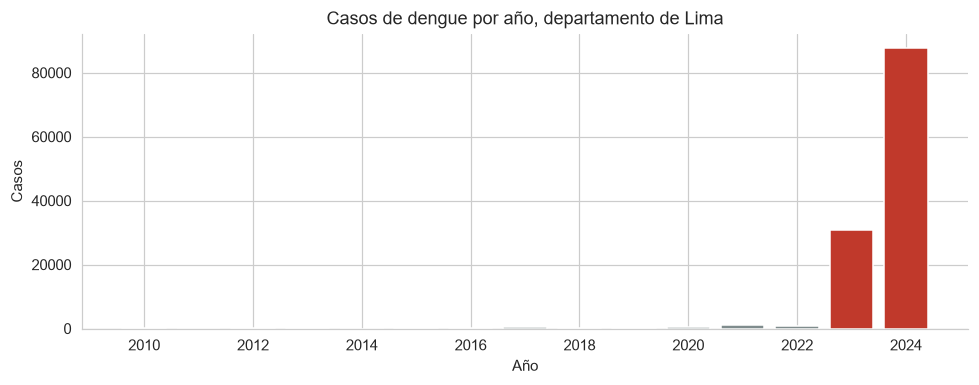

In [5]:
anual = lima.groupby('ano').casos.sum()
tot = anual.sum()
print(anual.to_string())
print(f"\nTotal 2010-2024: {tot:,}")
print(f"Casos en 2023-2024: {anual.loc[2023:2024].sum():,} ({anual.loc[2023:2024].sum()/tot:.1%})")
print(f"Casos 2010-2022 (13 años): {anual.loc[:2022].sum():,} ({anual.loc[:2022].sum()/tot:.1%})")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(anual.index, anual.values, color=[LIMA_C if a >= 2023 else OTRO_C for a in anual.index])
ax.set_title('Casos de dengue por año, departamento de Lima')
ax.set_ylabel('Casos'); ax.set_xlabel('Año')
plt.tight_layout(); plt.savefig(PLOTS / 'eda_casos_anuales_lima.png', dpi=150); plt.show()

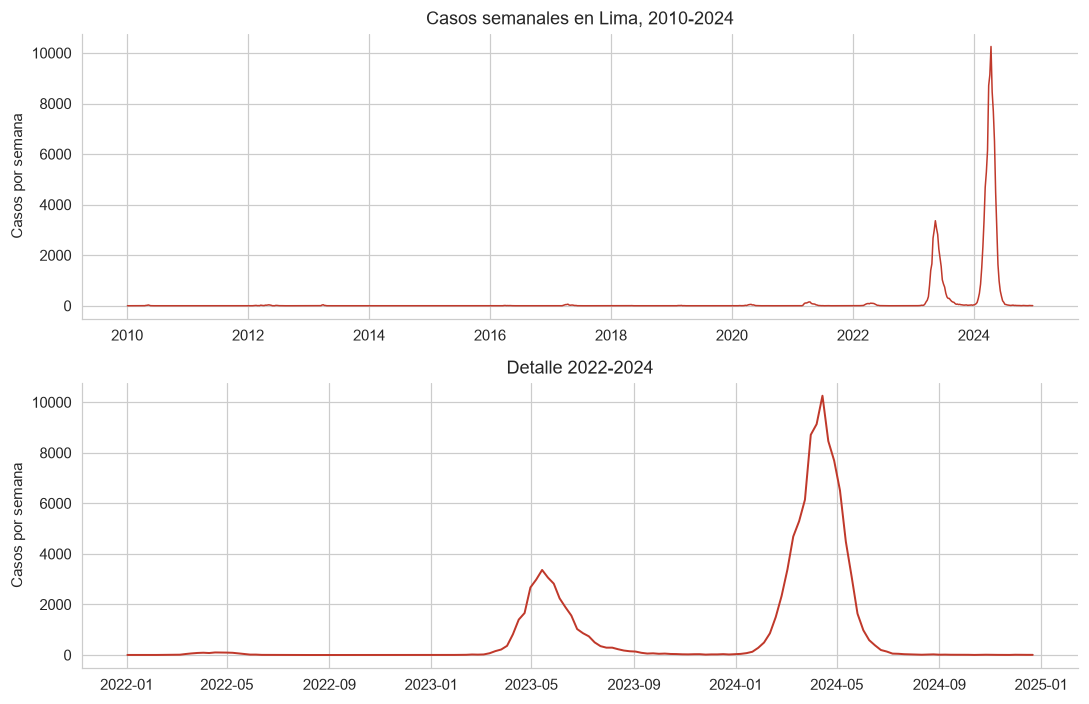

Pico: 10,256 casos en la semana 16 de 2024
Semanas con >=50 casos: 77 | >=10: 158 | total: 782


In [6]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6.5))
ax[0].plot(lima.fecha_inicio, lima.casos, color=LIMA_C, lw=1)
ax[0].set_title('Casos semanales en Lima, 2010-2024'); ax[0].set_ylabel('Casos por semana')
z = lima[lima.ano >= 2022]
ax[1].plot(z.fecha_inicio, z.casos, color=LIMA_C, lw=1.3)
ax[1].set_title('Detalle 2022-2024'); ax[1].set_ylabel('Casos por semana')
plt.tight_layout(); plt.savefig(PLOTS / 'eda_serie_semanal_lima.png', dpi=150); plt.show()

pico = lima.loc[lima.casos.idxmax()]
print(f"Pico: {int(pico.casos):,} casos en la semana {int(pico.semana)} de {int(pico.ano)}")
print(f"Semanas con >=50 casos: {(lima.casos >= 50).sum()} | >=10: {(lima.casos >= 10).sum()} | total: {len(lima)}")

### Distribución del objetivo (equivalente al desbalance en regresión)

En regresión no hay clases, pero la distribución del objetivo se lee igual que el desbalance: casi todas las semanas son "calmas" y unas pocas son extremas. Un modelo que predice siempre cero acierta en el 59 % de las semanas y falla donde importa.

Semanas con 0 casos: 463 (59%) | con >0: 319
Máximo / mediana: 10,256 / 0


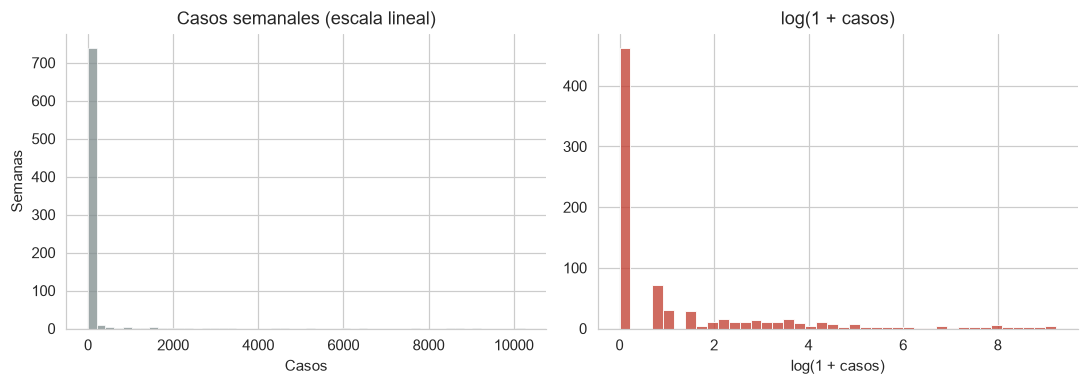

count      782.0
mean       156.1
std        894.5
min          0.0
25%          0.0
50%          0.0
75%          4.0
max      10256.0


In [7]:
n0 = (lima.casos == 0).sum()
print(f"Semanas con 0 casos: {n0} ({n0/len(lima):.0%}) | con >0: {len(lima)-n0}")
print(f"Máximo / mediana: {lima.casos.max():,.0f} / {lima.casos.median():.0f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
sns.histplot(lima.casos, bins=50, color=OTRO_C, ax=ax[0])
ax[0].set_title('Casos semanales (escala lineal)'); ax[0].set_xlabel('Casos'); ax[0].set_ylabel('Semanas')
sns.histplot(np.log1p(lima.casos), bins=40, color=LIMA_C, ax=ax[1])
ax[1].set_title('log(1 + casos)'); ax[1].set_xlabel('log(1 + casos)'); ax[1].set_ylabel('')
plt.tight_layout(); plt.savefig(PLOTS / 'eda_distribucion_casos.png', dpi=150); plt.show()
print(lima.casos.describe().round(1).to_string())

## 4. Outliers

Se detectan con los dos métodos del curso, IQR (fuera de [Q1 - 1.5 IQR, Q3 + 1.5 IQR]) y z-score (|z| > 3), y luego se decide qué hacer. Un outlier no es automáticamente un error.

In [8]:
vars_out = ['casos', 'temp_media', 'temp_max', 'temp_min', 'precip_total', 'hum_rel', 'viento']
d = lima[vars_out].dropna()

Q1, Q3 = d.quantile(0.25), d.quantile(0.75)
IQR = Q3 - Q1
fuera_iqr = (d < Q1 - 1.5 * IQR) | (d > Q3 + 1.5 * IQR)
fuera_z = pd.DataFrame(np.abs(stats.zscore(d)), columns=d.columns) > 3

resumen = pd.DataFrame({'IQR (n)': fuera_iqr.sum(), 'IQR (%)': (fuera_iqr.mean() * 100).round(1),
                        'z>3 (n)': fuera_z.sum(), 'z>3 (%)': (fuera_z.mean() * 100).round(1)})
resumen

,IQR (n),IQR (%),z>3 (n),z>3 (%)
casos,151,19.3,15,1.9
temp_media,0,0.0,0,0.0
temp_max,1,0.1,0,0.0
temp_min,0,0.0,0,0.0
precip_total,78,10.0,19,2.4
hum_rel,0,0.0,0,0.0
viento,0,0.0,0,0.0


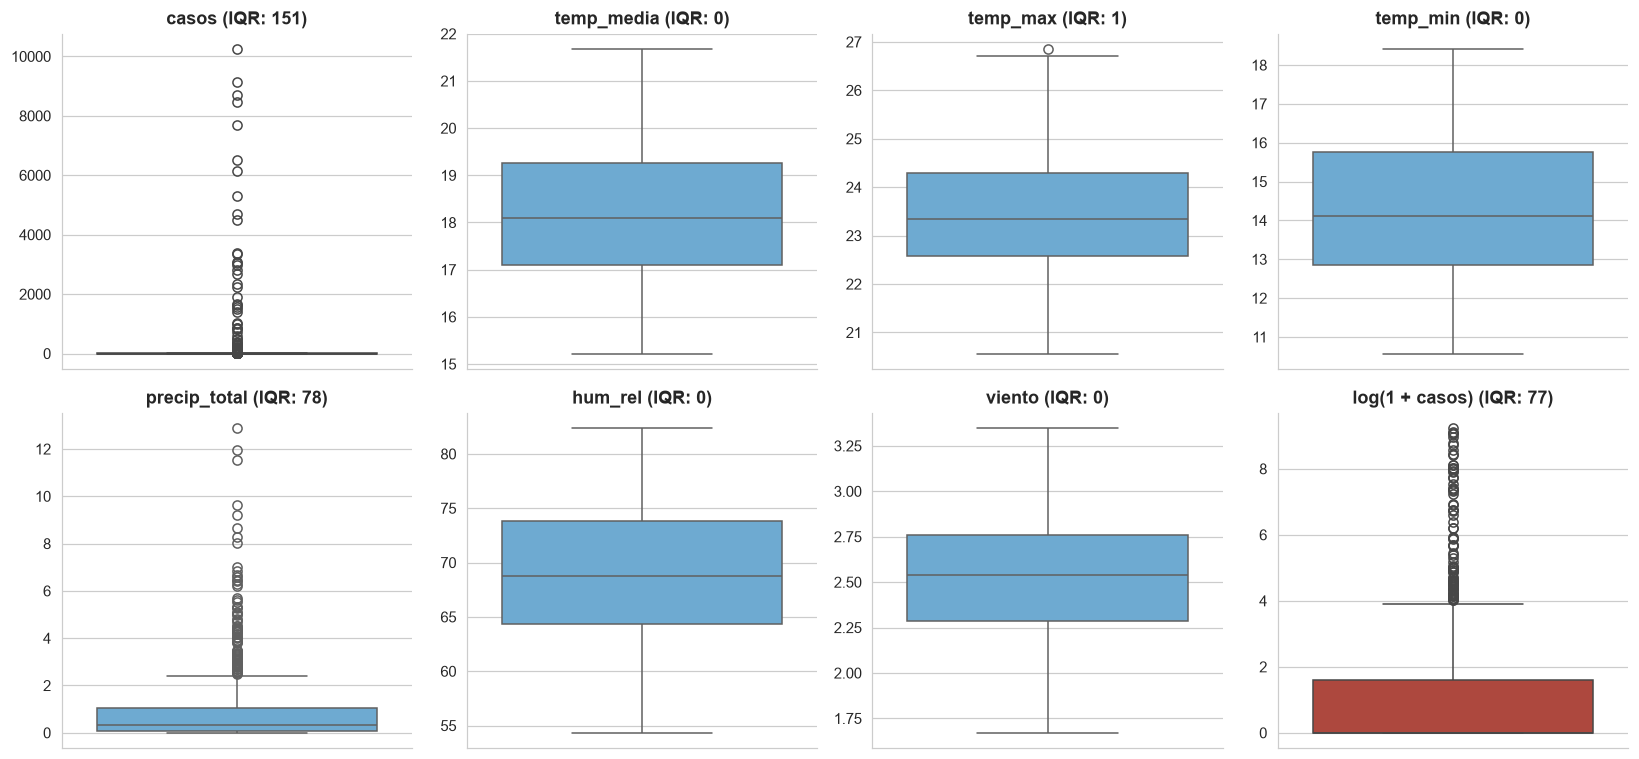

Rangos del clima (regla de dominio: temperatura 0-45 C, humedad 0-100 %, lluvia >= 0):
     temp_media  temp_max  temp_min  hum_rel  precip_total
min        15.2      20.6      10.6     54.3           0.0
max        21.7      26.9      18.4     82.4          12.9


In [9]:
lc = np.log1p(d['casos'])
lq1, lq3 = lc.quantile([0.25, 0.75])
n_iqr_log = int(((lc < lq1 - 1.5 * (lq3 - lq1)) | (lc > lq3 + 1.5 * (lq3 - lq1))).sum())

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
axes = axes.flatten()
for i, col in enumerate(vars_out):
    sns.boxplot(y=d[col], ax=axes[i], color=LIMA_C if col == 'casos' else '#5DADE2')
    axes[i].set_title(f"{col} (IQR: {fuera_iqr[col].sum()})", fontweight='bold')
    axes[i].set_ylabel('')
sns.boxplot(y=lc, ax=axes[7], color=LIMA_C)
axes[7].set_title(f"log(1 + casos) (IQR: {n_iqr_log})", fontweight='bold')
axes[7].set_ylabel('')
plt.tight_layout(); plt.savefig(PLOTS / 'eda_boxplots.png', dpi=150); plt.show()

print('Rangos del clima (regla de dominio: temperatura 0-45 C, humedad 0-100 %, lluvia >= 0):')
print(d[['temp_media', 'temp_max', 'temp_min', 'hum_rel', 'precip_total']].agg(['min', 'max']).round(1).to_string())

**Decisión sobre outliers.**

- **Casos:** el IQR marca 151 semanas (19 %) y el z-score solo 15 (1.9 %). El IQR es más estricto porque la distribución es muy asimétrica y la desviación estándar se infla con los propios extremos. Esas semanas son las de la epidemia de 2023-2024, no errores, y son justo lo que se quiere predecir. **No se eliminan ni se recortan** (winsorizar aplanaría los picos). Se aplica `log1p` para comprimir la cola larga.
- **Clima:** las temperaturas y la humedad casi no tienen outliers. La precipitación sí (78 semanas por IQR) porque la lluvia en Lima es escasa y las semanas con llovizna salen "fuera de caja"; son valores reales y dentro de rangos físicos (la regla de dominio gana sobre el IQR). Se conservan.
- Al conservar los extremos, el `StandardScaler` se ve afectado por ellos; si hace falta se puede probar `RobustScaler`.

## 5. Escalas de las variables

Las variables numéricas tienen rangos muy distintos.

In [10]:
num_cols = ['casos', 'temp_media', 'temp_max', 'temp_min', 'precip_total', 'precip_max_d',
            'dias_lluvia', 'hum_rel', 'viento', 'icen']
escalas = pd.DataFrame({'Mín': lima[num_cols].min(), 'Máx': lima[num_cols].max()})
escalas['Rango'] = escalas['Máx'] - escalas['Mín']
escalas.sort_values('Rango', ascending=False).round(2)

,Mín,Máx,Rango
casos,0.00,10256.00,10256.00
hum_rel,54.34,82.38,28.04
precip_total,0.00,12.89,12.89
precip_max_d,0.00,8.47,8.47
temp_min,10.57,18.42,7.85
temp_media,15.22,21.68,6.46
temp_max,20.56,26.86,6.29
icen,-1.66,2.92,4.58
dias_lluvia,0.00,3.33,3.33
viento,1.67,3.35,1.68


**Decisión.** Los rangos van de unas decenas (humedad, temperatura) a miles (casos). KNN y Ridge dependen de distancias o del tamaño de los coeficientes, así que necesitan `StandardScaler` **dentro del `Pipeline`** (se ajusta solo con train). El árbol no lo necesita porque compara cada variable contra un umbral.

## 6. Correlación entre variables y multicolinealidad

La regresión lineal falla cuando varias variables miden casi lo mismo (coeficientes inflados que se compensan). Se revisa con un heatmap, como en el tutorial de regresión.

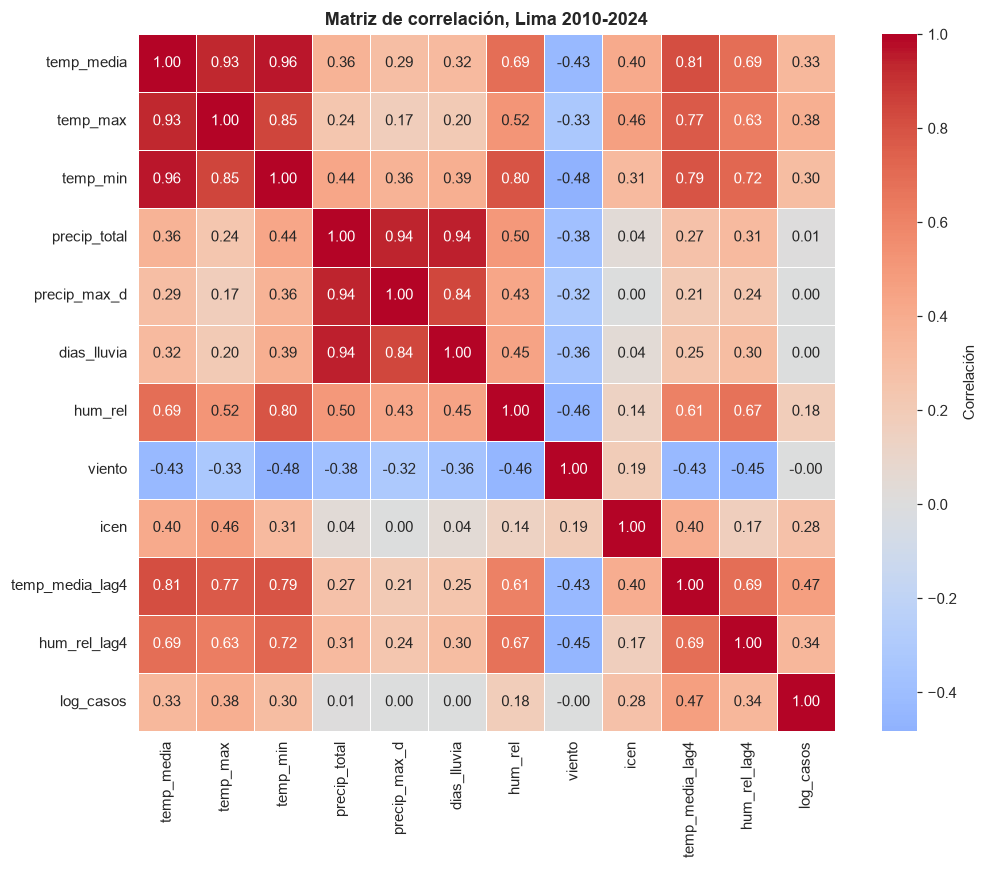

Pares de variables con |r| > 0.9:
temp_media    temp_min        0.96
precip_total  dias_lluvia     0.94
              precip_max_d    0.94
temp_media    temp_max        0.93


In [11]:
feats = ['temp_media', 'temp_max', 'temp_min', 'precip_total', 'precip_max_d', 'dias_lluvia',
         'hum_rel', 'viento', 'icen', 'temp_media_lag4', 'hum_rel_lag4']
m = lima.dropna().copy()
m['log_casos'] = np.log1p(m.casos)
corr = m[feats + ['log_casos']].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Correlación'})
ax.set_title('Matriz de correlación, Lima 2010-2024', fontweight='bold')
plt.tight_layout(); plt.savefig(PLOTS / 'eda_correlacion_heatmap.png', dpi=150); plt.show()

c = corr.loc[feats, feats].where(np.triu(np.ones((len(feats), len(feats))), 1).astype(bool)).stack()
altas = c[c.abs() > 0.9].sort_values(key=abs, ascending=False).round(2)
print('Pares de variables con |r| > 0.9:')
print(altas.to_string())

**Decisión.** Hay grupos de variables casi duplicadas: las temperaturas entre sí (media, mínima y máxima, r entre 0.93 y 0.96) y las tres variables de lluvia entre sí (r = 0.94). Para los modelos lineales se usará **Ridge** (penaliza coeficientes grandes) y, como alternativa, se dejará una sola variable por grupo. Los árboles no sufren este problema.

## 7. Clima y casos

Se correlaciona `log(1 + casos)` en la semana *t* con el clima de la semana *t - k* (k de 0 a 12). Solo se usa 2023-2024, donde hay señal; con una sola ola, la correlación es orientativa y no prueba causalidad.

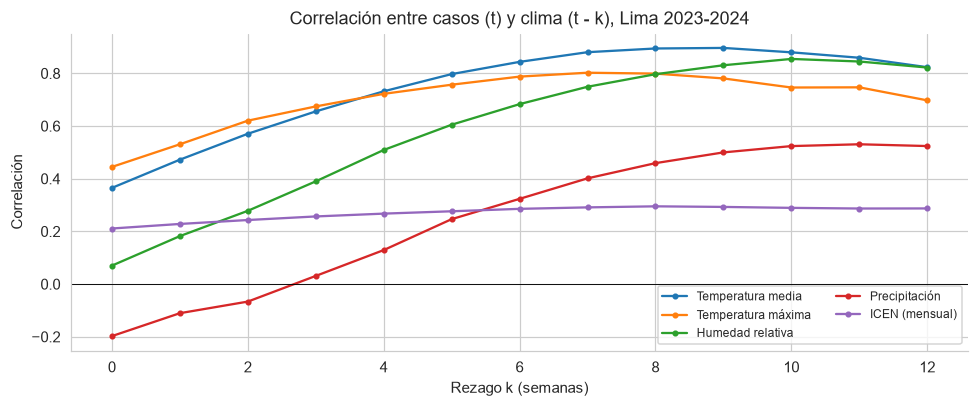

Rezago con mayor |correlación| por variable:
  Temperatura media    k= 9  r=+0.90
  Temperatura máxima   k= 7  r=+0.80
  Humedad relativa     k=10  r=+0.85
  Precipitación        k=11  r=+0.53
  ICEN (mensual)       k= 8  r=+0.30


In [12]:
z = lima[lima.ano >= 2023].reset_index(drop=True)
y = np.log1p(z.casos)
vars_ = {'temp_media': 'Temperatura media', 'temp_max': 'Temperatura máxima',
         'hum_rel': 'Humedad relativa', 'precip_total': 'Precipitación', 'icen': 'ICEN (mensual)'}
lags = range(0, 13)
res = pd.DataFrame({v: [y.corr(z[v].shift(k)) for k in lags] for v in vars_}, index=lags)

fig, ax = plt.subplots(figsize=(9, 3.8))
for v, nombre in vars_.items():
    ax.plot(res.index, res[v], marker='o', ms=3, label=nombre)
ax.axhline(0, color='k', lw=0.6)
ax.set_title('Correlación entre casos (t) y clima (t - k), Lima 2023-2024')
ax.set_xlabel('Rezago k (semanas)'); ax.set_ylabel('Correlación'); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(PLOTS / 'eda_correlacion_lags.png', dpi=150); plt.show()

mejor = res.abs().idxmax()
print('Rezago con mayor |correlación| por variable:')
for v, k in mejor.items():
    print(f"  {vars_[v]:20} k={k:2d}  r={res.loc[k, v]:+.2f}")

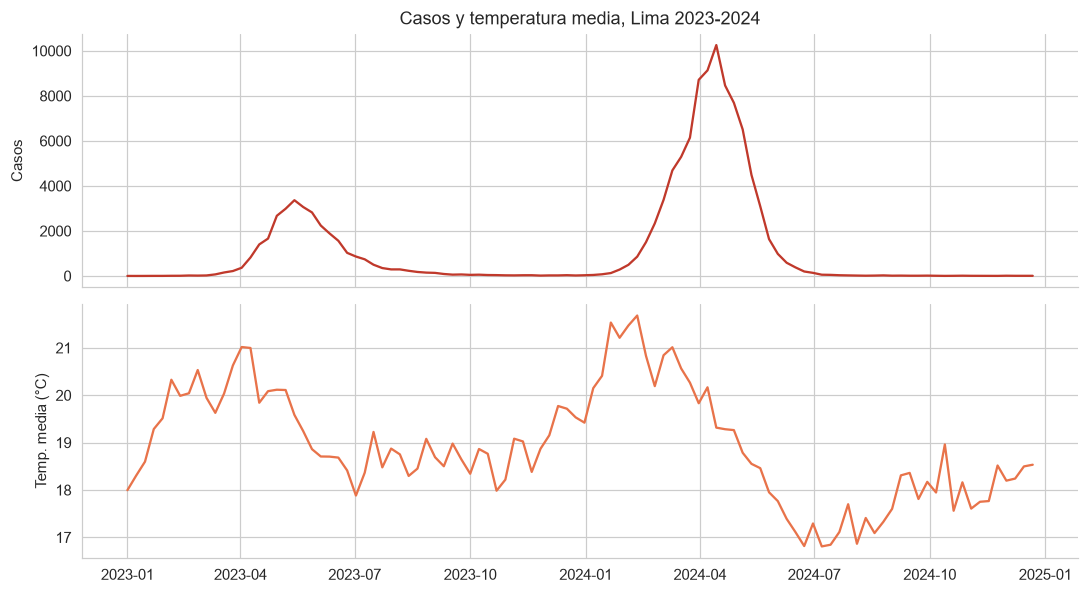

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax[0].plot(z.fecha_inicio, z.casos, color=LIMA_C); ax[0].set_ylabel('Casos')
ax[0].set_title('Casos y temperatura media, Lima 2023-2024')
ax[1].plot(z.fecha_inicio, z.temp_media, color='#E8734A'); ax[1].set_ylabel('Temp. media (°C)')
plt.tight_layout(); plt.savefig(PLOTS / 'eda_casos_vs_temperatura.png', dpi=150); plt.show()

### Estacionalidad: 2023 frente a 2024

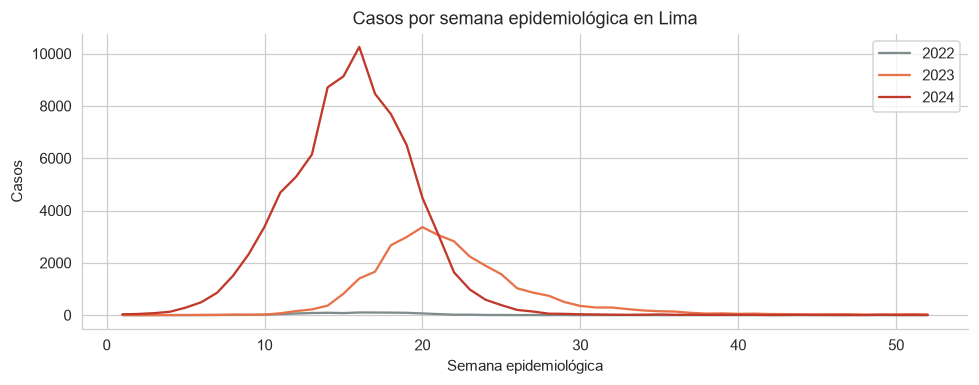

2023 -> semana pico: 20 | casos pico: 3364
2024 -> semana pico: 16 | casos pico: 10256


In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for ano, col in [(2022, OTRO_C), (2023, '#E8734A'), (2024, LIMA_C)]:
    s = lima[lima.ano == ano]
    ax.plot(s.semana, s.casos, label=str(ano), color=col)
ax.set_title('Casos por semana epidemiológica en Lima'); ax.set_xlabel('Semana epidemiológica')
ax.set_ylabel('Casos'); ax.legend()
plt.tight_layout(); plt.savefig(PLOTS / 'eda_estacionalidad_lima.png', dpi=150); plt.show()
for ano in (2023, 2024):
    s = lima[lima.ano == ano]
    print(ano, '-> semana pico:', int(s.loc[s.casos.idxmax(), 'semana']), '| casos pico:', int(s.casos.max()))

## 8. Lima frente a otros departamentos

Lima tiene una sola ola. Otros departamentos tienen varias (por ejemplo Piura en 2015, 2017 y 2023) y pueden servir para entrenar si su clima es parecido al de Lima.

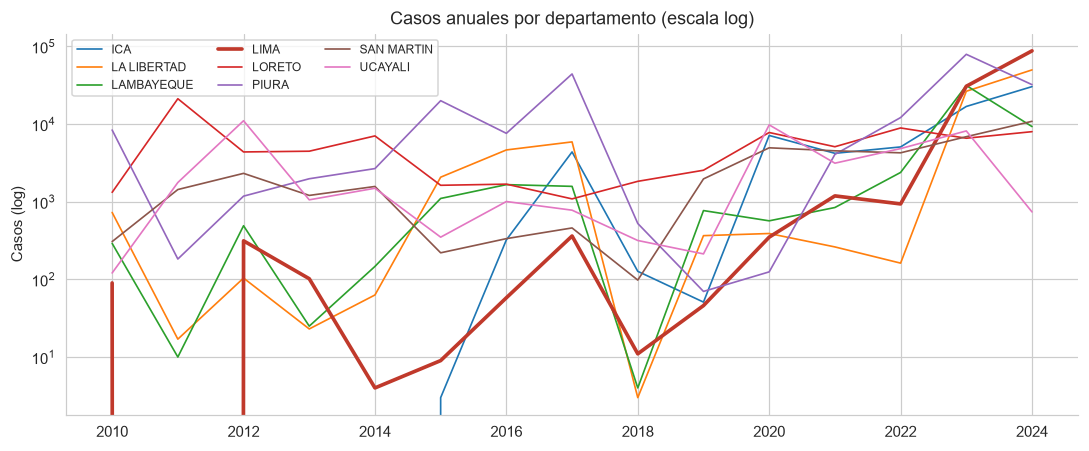

departamento,ICA,LA LIBERTAD,LAMBAYEQUE,LIMA,LORETO,PIURA,SAN MARTIN,UCAYALI
ano,,,,,,,,
2010,0,728,291,90,1322,8393,307,121
2011,0,17,10,0,21245,183,1437,1770
2012,0,104,491,314,4382,1181,2322,11056
2013,0,23,25,102,4479,1979,1207,1059
2014,0,63,147,4,7049,2675,1574,1493
2015,3,2073,1103,9,1630,20042,220,350
2016,323,4650,1662,58,1686,7610,335,1007
2017,4384,5904,1579,362,1089,44275,460,779
2018,127,3,4,11,1833,525,98,317


In [15]:
top = deps.groupby('departamento').casos.sum().nlargest(8).index.tolist()
if 'LIMA' not in top: top.append('LIMA')
a = deps[deps.departamento.isin(top)].pivot_table(index='ano', columns='departamento',
                                                  values='casos', aggfunc='sum')
fig, ax = plt.subplots(figsize=(10, 4.2))
for c in a.columns:
    ax.plot(a.index, a[c], lw=2.4 if c == 'LIMA' else 1.1,
            color=LIMA_C if c == 'LIMA' else None, label=c)
ax.set_yscale('log'); ax.set_title('Casos anuales por departamento (escala log)')
ax.set_ylabel('Casos (log)'); ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS / 'eda_lima_vs_departamentos.png', dpi=150); plt.show()
a.round(0).astype(int)

### Departamentos con clima parecido al de Lima

Se compara el clima promedio 2010-2024 (temperatura media, precipitación semanal y humedad) con el de Lima, estandarizando las variables. Distancia menor = clima más parecido. Los departamentos con sierra aparecen "parecidos" porque se promedian todas sus celdas; hay que revisar caso por caso.

In [16]:
f = ['temp_media', 'precip_total', 'hum_rel']
zc = (clim[f] - clim[f].mean()) / clim[f].std()
lima_z = zc[clim.departamento == 'LIMA'].iloc[0]
clim['distancia_a_lima'] = np.sqrt(((zc - lima_z) ** 2).sum(axis=1))
casos_dep = deps.groupby('departamento').casos.sum().rename('casos_2010_2024')
casos_2324 = deps[deps.ano >= 2023].groupby('departamento').casos.sum().rename('casos_2023_2024')
tabla = (clim.merge(casos_dep, on='departamento').merge(casos_2324, on='departamento')
         .sort_values('distancia_a_lima').round(2))
tabla[['departamento', 'temp_media', 'precip_total', 'hum_rel', 'distancia_a_lima',
       'casos_2010_2024', 'casos_2023_2024']].head(8).reset_index(drop=True)

,departamento,temp_media,precip_total,hum_rel,distancia_a_lima,casos_2010_2024,casos_2023_2024
0,LIMA,18.19,0.91,69.03,0.00,122073,118599
1,CALLAO,18.42,0.60,67.46,0.22,8138,8112
2,ANCASH,19.10,3.32,70.14,0.32,36510,30447
3,LA LIBERTAD,18.39,5.12,71.61,0.53,91178,76433
4,CAJAMARCA,18.95,7.46,68.82,0.62,24604,10301
5,AREQUIPA,16.47,2.25,65.27,0.63,28,21
6,ICA,19.02,1.70,62.90,0.86,68620,47296
7,JUNIN,16.22,7.52,73.52,0.95,24606,6911


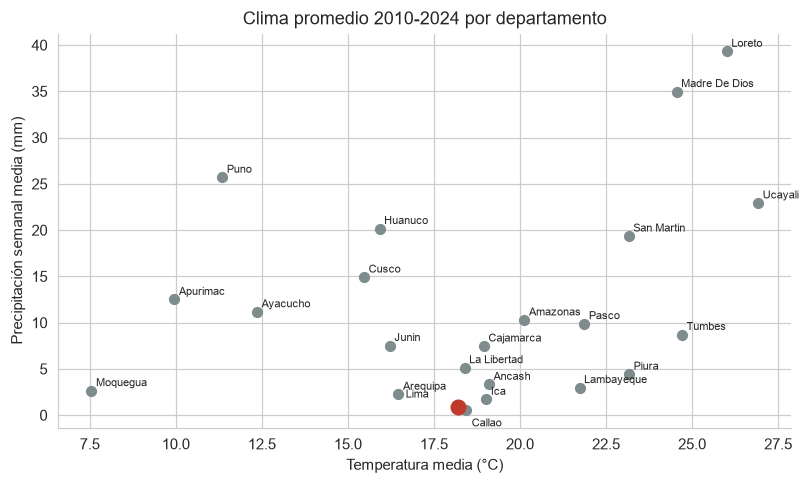

In [17]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(tabla.temp_media, tabla.precip_total, s=40, color=OTRO_C)
l = tabla[tabla.departamento == 'LIMA']
ax.scatter(l.temp_media, l.precip_total, s=90, color=LIMA_C, zorder=3)
desp = {'LIMA': (-34, 6), 'CALLAO': (4, -11)}
for _, r in tabla.iterrows():
    ax.annotate(r.departamento.title(), (r.temp_media, r.precip_total), fontsize=7,
                xytext=desp.get(r.departamento, (3, 3)), textcoords='offset points')
ax.set_xlabel('Temperatura media (°C)'); ax.set_ylabel('Precipitación semanal media (mm)')
ax.set_title('Clima promedio 2010-2024 por departamento')
plt.tight_layout(); plt.savefig(PLOTS / 'eda_clima_departamentos.png', dpi=150); plt.show()

## 9. Separar X e y y partir train / validación / test

Se sigue el procedimiento del tutorial de regresión: se define `X` (variables) e `y` (objetivo) y se parte con `train_test_split` y `random_state=42` en dos pasos (80 % train, 10 % validación, 10 % test).

- **Objetivo (`y`):** `objetivo` = `log(1 + casos)` 4 semanas después de la semana de la fila.
- **Variables (`X`):** clima de la semana y sus rezagos, rezagos de `log_casos`, media móvil de 4 semanas, ICEN y la semana del año como seno y coseno.
- **Fuera de `X`:** `departamento`, `ano`, `semana` y `fecha_inicio` solo identifican la fila. `departamento` es categórica, así que si se quiere usar como variable hay que codificarla dentro del `Pipeline`.

El `StandardScaler` no se aplica aquí: se ajusta solo con train dentro del `Pipeline`, para no filtrar información de validación ni de test.

In [18]:
modelado = pd.read_csv(PROC / 'modelado.csv', parse_dates=['fecha_inicio'])
print('Filas, columnas:', modelado.shape, '| valores faltantes:', int(modelado.isna().sum().sum()))
print(modelado.groupby('departamento').size().to_string())

X = modelado.drop(columns=['objetivo', 'departamento', 'ano', 'semana', 'fecha_inicio'])
y = modelado['objetivo']

# Separar 20% para val+test (queda 80% para train)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.20, random_state=42)
# Del 20% restante, dividir en 50/50 (val y test)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

resumen = pd.DataFrame({
    'Conjunto': ['Train', 'Validación', 'Test', 'Total'],
    'Filas': [len(X_train), len(X_val), len(X_test), len(X)],
    'Variables': [X_train.shape[1]] * 3 + [X.shape[1]],
    'Media del objetivo': [y_train.mean(), y_val.mean(), y_test.mean(), y.mean()]})
resumen.round(3)

Filas, columnas: (3850, 33) | valores faltantes: 0
departamento
ANCASH         770
CALLAO         770
ICA            770
LA LIBERTAD    770
LIMA           770


,Conjunto,Filas,Variables,Media del objetivo
0,Train,3080,28,1.249
1,Validación,385,28,1.317
2,Test,385,28,1.156
3,Total,3850,28,1.247


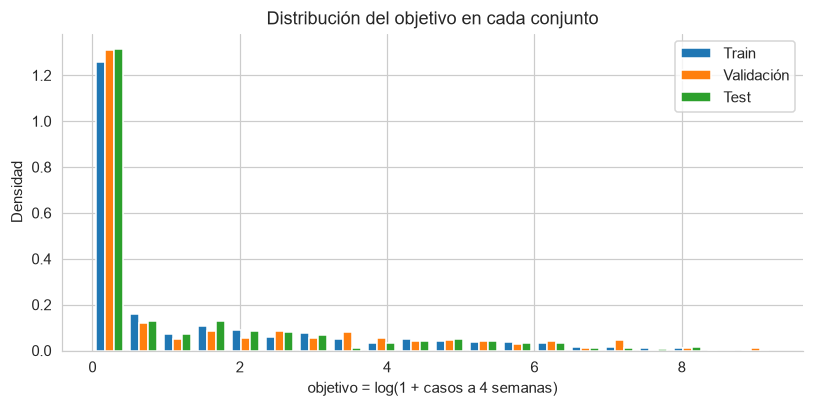

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist([y_train, y_val, y_test], bins=20, density=True, label=['Train', 'Validación', 'Test'])
ax.set_xlabel('objetivo = log(1 + casos a 4 semanas)'); ax.set_ylabel('Densidad')
ax.set_title('Distribución del objetivo en cada conjunto'); ax.legend()
plt.tight_layout(); plt.savefig(PLOTS / 'eda_split_objetivo.png', dpi=150); plt.show()

Los tres conjuntos tienen una distribución del objetivo parecida, que es lo que se espera de un corte aleatorio.

**Limitación a tener presente.** Como los datos son semanas consecutivas, un corte aleatorio pone semanas vecinas (casi iguales) en train y en test, y el modelo puede salir mejor de lo que sería prediciendo el futuro real. Se aplica igual que en el curso, y al comparar el resultado de validación cruzada con el de test (como en la pregunta 11 del Lab 3) conviene revisar si el modelo generaliza.

## 10. Conclusiones del EDA

1. **Calidad.** `ubigeo` está completo y es consistente si se lee como texto. `localidad` está vacía en el 39 % de los casos de Lima, así que no se usa. El 20.9 % de las filas de Lima está duplicado y no se elimina, porque cada fila es un caso.
2. **Faltantes.** Solo faltan los rezagos de clima de las 8 primeras semanas de 2010 (1 % de las filas). Se eliminan en vez de imputar (menos del 5 % de las filas).
3. **Una sola ola real.** El 97.2 % de los casos de Lima 2010-2024 (118,599 de 122,073) ocurre en 2023-2024. El 59 % de las semanas tiene 0 casos y el máximo es 10,256 (semana 16 de 2024). Se recomienda modelar `log(1 + casos)` y comparar siempre contra un baseline de persistencia.
4. **Outliers.** Las semanas "extremas" de casos (151 por IQR, 15 por z-score) son la epidemia, no errores. Se conservan. Lo mismo con la lluvia, que en Lima es escasa e irregular.
5. **Escalas y multicolinealidad.** Los rangos son muy distintos (casos hasta 10,256 frente a viento entre 1.7 y 3.3), así que KNN y Ridge necesitan `StandardScaler` dentro del `Pipeline`. Las tres temperaturas (r entre 0.93 y 0.96) y las tres variables de lluvia (r = 0.94) están casi duplicadas, por eso se propone Ridge y probar con una variable por grupo.
6. **Clima y casos.** La temperatura media y máxima y la humedad correlacionan fuerte con los casos 7 a 10 semanas después (r entre 0.80 y 0.90). Es consistente con la biología del vector, pero sale de solo dos temporadas, así que es sobre todo estacionalidad compartida y no evidencia causal. La precipitación (r = 0.53) y el ICEN (r = 0.30) son más débiles.
7. **Otros departamentos.** Con clima parecido al de Lima (temperatura, precipitación y humedad) están Callao, Ancash, La Libertad e Ica. Cajamarca, Arequipa y Junín aparecen cerca solo porque sus promedios mezclan costa y sierra. Departamentos de entrenamiento: Lima + Ica + La Libertad + Ancash + Callao.
8. **Partición.** Se arma `X` (28 variables) e `y` (`log(1 + casos)` a 4 semanas) y se parte con `train_test_split` y `random_state=42`: 80 % train, 10 % validación y 10 % test (3,080 / 385 / 385 filas), como en el tutorial de regresión. La media del objetivo es parecida en los tres conjuntos. Ojo: al ser semanas consecutivas, el corte aleatorio pone semanas vecinas en train y test, por lo que el resultado puede ser más optimista que predecir el futuro real.
9. **Limitaciones.** Los datos llegan hasta 2024 (existen datos 2025-2026 en boletines del CDC, sin integrar). El clima es MERRA-2, con celdas de unos 55 km, poco fino para los 81 distritos de Lima. El resultado depende de una sola ola.

**Siguientes pasos:** baseline de persistencia y autorregresivo, y los modelos aprendidos del curso (Ridge, árbol, KNN) en `02_modelos.ipynb` con `Pipeline` y `KFold`, con la partición del punto 8.
